# 🛒 Shoplifting & Theft Detection in Video Surveillance
## Temporal Deep Learning with 3D CNNs, CNN-RNNs, and Video Transformers from Scratch

---

### 📌 Project Objective
Build an end-to-end video classification pipeline capable of distinguishing between **Normal Shopping Behavior** (browsing, walking, inspecting items) and **Shoplifting / Theft Acts** (reaching, concealing items into bags or pockets, rapid flight) using temporal deep learning architectures built **from scratch in PyTorch**.

### 📋 Assignment Tasks & Completion Requirements
1. **Video Dataset Exploration (EDA)**:
   - Quantify number of clips per class (`Normal` vs `Shoplifting`).
   - Characterize clip duration distribution (seconds, total frame counts, FPS).
   - Analyze spatial frame resolution ($W \times H$) and aspect ratios.
2. **Uniform Frame Sampling Strategy**:
   - Given variable total frames $N$ and target count $T$, compute a uniform skip interval so sampled frames span the full duration evenly.
   - Robustly handle arbitrary video lengths ($N \ge T$, $N < T$).
   - **Verification**: Verified across diverse clip durations.
3. **Consistent Spatial Augmentation**:
   - Apply synchronized spatial transformations (identical random flip, crop, and color jitter) across all $T$ frames of a clip to preserve physical continuity.
   - **Verification**: Verified via code checks and visual side-by-side filmstrips.
4. **PyTorch Dataset & DataLoader**:
   - Returns a tensor of shape `(T, C, H, W)` per video clip.
   - **Verification**: Verified shape consistency across batches.
5. **Architectures Built from Scratch**:
   - **3D CNN (`SpatiotemporalCNN3D`)**: 3D convolutions modeling joint spatial and temporal cues.
   - **CNN + BiLSTM / GRU (`CNN_RNN_Classifier`)**: Custom 2D spatial feature extractor with Bidirectional RNN and Temporal Attention Pooling.
   - **Video Transformer (`VideoTransformerClassifier`)**: Spatio-temporal self-attention mechanism.
6. **Training & Multi-Metric Evaluation**:
   - Train with Binary Cross-Entropy with Logits, AdamW, and Cosine Annealing.
   - Evaluate with **Accuracy, Precision, Recall, F1-Score, Confusion Matrix, and ROC-AUC**.


---
## 1. Environment Setup, Dependencies & Reproducibility
We import core libraries (`torch`, `torchvision`, `cv2`, `numpy`, `matplotlib`, `seaborn`, `sklearn`) and fix all random seeds for exact experimental reproducibility.


In [24]:
import os
import sys
import glob
import math
import random
import time
from typing import Tuple, List, Dict, Optional

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
import torchvision.transforms.functional as TF
import torchvision.transforms as transforms

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)

# Set random seeds for deterministic reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f" PyTorch Version : {torch.__version__}")
print(f" OpenCV Version  : {cv2.__version__}")
print(f" Compute Device  : {device}")
if torch.cuda.is_available():
    print(f" GPU Device Name : {torch.cuda.get_device_name(0)}")


 PyTorch Version : 2.11.0+cu128
 OpenCV Version  : 4.14.0
 Compute Device  : cuda
 GPU Device Name : Tesla T4


---
## 2. Dataset Management & Video Path Configuration

Surveillance video datasets for shoplifting detection are organized into two classes:
- **Normal Shopping Behavior** (`non shop lifters` / `Normal`) $\rightarrow$ Class Label: **0**
- **Shoplifting / Theft Acts** (`shop lifters` / `Shoplifting`) $\rightarrow$ Class Label: **1**

### Dataset Path Configuration
The notebook automatically detects:
1. **Kaggle Environment Path**:
   - `/kaggle/input/datasets/betermoawad/detect/Shop DataSet`
   - `/kaggle/input/detect/Shop DataSet`
2. **Local Workstation Paths**:
   - `D:/Downloads/Shop DataSet`
   - `./Shop DataSet`
3. **Automated Fallback**:
   - If no video files are found in any candidate path, an automated surveillance video generator renders synthetic clips using OpenCV so the notebook executes end-to-end anywhere.


In [25]:
# User-specified Kaggle dataset root path
KAGGLE_DATASET_DIR = "/kaggle/input/datasets/betermoawad/detect/Shop DataSet"

# Candidate search paths in priority order
CANDIDATE_PATHS = [
    KAGGLE_DATASET_DIR,
    "/kaggle/input/detect/Shop DataSet",
    os.path.join("D:", os.sep, "Downloads", "Shop DataSet"),
    os.path.join(".", "Shop DataSet"),
    os.path.join("..", "Shop DataSet"),
    os.path.join(".", "shoplifting_dataset")
]

DATASET_DIR = None
for candidate in CANDIDATE_PATHS:
    if os.path.exists(candidate):
        has_subfolders = any(
            os.path.exists(os.path.join(candidate, sub))
            for sub in ["non shop lifters", "shop lifters", "Normal", "Shoplifting"]
        )
        if has_subfolders:
            DATASET_DIR = candidate
            break

if DATASET_DIR is None:
    DATASET_DIR = KAGGLE_DATASET_DIR if os.path.exists("/kaggle") else os.path.join("D:", os.sep, "Downloads", "Shop DataSet")

print(f" Active Dataset Directory: {DATASET_DIR}")
print(f" Path Exists on System    : {os.path.exists(DATASET_DIR)}")


 Active Dataset Directory: /kaggle/input/datasets/betermoawad/detect/Shop DataSet
 Path Exists on System    : True


In [26]:
def generate_synthetic_fallback_if_empty(dataset_root: str, num_per_class: int = 15):
    """
    Generates synthetic surveillance video clips if no real videos are found on disk.
    Ensures complete self-containment and zero-dependency execution.
    """
    normal_dir = os.path.join(dataset_root, "non shop lifters")
    theft_dir = os.path.join(dataset_root, "shop lifters")
    
    os.makedirs(normal_dir, exist_ok=True)
    os.makedirs(theft_dir, exist_ok=True)
    
    existing_normal = len(glob.glob(os.path.join(normal_dir, "*.mp4")))
    existing_theft = len(glob.glob(os.path.join(theft_dir, "*.mp4")))
    
    if existing_normal > 0 or existing_theft > 0:
        print(f" Found existing dataset: {existing_normal} Non-Shoplifting clips, {existing_theft} Shoplifting clips.")
        return

    print(" No videos found. Rendering synthetic surveillance clips for demonstration...")
    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    
    # Generate Normal Clips
    for i in range(num_per_class):
        num_frames = random.choice([35, 55, 80, 110])
        fps = 25.0
        w, h = 128, 128
        out = cv2.VideoWriter(os.path.join(normal_dir, f"shop_lifter_n_{i}.mp4"), fourcc, fps, (w, h))
        start_x, end_x = random.randint(15, 30), random.randint(85, 110)
        y_pos = random.randint(55, 75)
        
        for f in range(num_frames):
            alpha = f / float(max(1, num_frames - 1))
            cur_x = int(start_x + alpha * (end_x - start_x))
            frame = np.full((h, w, 3), 40, dtype=np.uint8)
            cv2.rectangle(frame, (10, 10), (118, 38), (80, 80, 90), -1)
            for item_x in range(15, 115, 12):
                cv2.rectangle(frame, (item_x, 18), (item_x + 8, 34), (180, 140, 80), -1)
            cv2.circle(frame, (cur_x, y_pos - 12), 7, (210, 200, 180), -1)
            cv2.rectangle(frame, (cur_x - 5, y_pos - 5), (cur_x + 5, y_pos + 18), (70, 130, 180), -1)
            out.write(frame)
        out.release()
        
    # Generate Shoplifting Clips
    for i in range(num_per_class):
        num_frames = random.choice([40, 65, 90, 120])
        fps = 25.0
        w, h = 128, 128
        out = cv2.VideoWriter(os.path.join(theft_dir, f"shop_lifter_{i}.mp4"), fourcc, fps, (w, h))
        for f in range(num_frames):
            progress = f / float(max(1, num_frames - 1))
            frame = np.full((h, w, 3), 40, dtype=np.uint8)
            cv2.rectangle(frame, (10, 10), (118, 38), (80, 80, 90), -1)
            if progress < 0.55:
                cv2.rectangle(frame, (60, 20), (68, 34), (50, 220, 50), -1)
            actor_x = int(20 + progress * 95)
            actor_y = 65
            cv2.circle(frame, (actor_x, actor_y - 12), 7, (210, 190, 170), -1)
            cv2.rectangle(frame, (actor_x - 5, actor_y - 5), (actor_x + 5, actor_y + 18), (140, 40, 40), -1)
            out.write(frame)
        out.release()

if not os.path.exists(DATASET_DIR):
    os.makedirs(DATASET_DIR, exist_ok=True)
    generate_synthetic_fallback_if_empty(DATASET_DIR)


---
## 3. Task 1: Video Dataset Exploration (EDA)

We systematically inspect the video dataset by extracting metadata with `cv2.VideoCapture`:
1. **Clip Counts**: Balance between `non shop lifters` (Normal: class $0$) and `shop lifters` (Shoplifting: class $1$).
2. **Clip Durations**: Total frames $N$, frame rate (FPS), and duration in seconds:
   $$\text{Duration (seconds)} = \frac{\text{Total Frames}}{\text{FPS}}$$
3. **Spatial Resolution**: Width, height, and aspect ratio of surveillance cameras.


In [27]:
def inspect_video_dataset(
    dataset_root: str,
    max_samples_per_class: Optional[int] = None
) -> pd.DataFrame:
    """
    Scans dataset directories recursively (using os.walk), extracts metadata for EVERY video clip
    using OpenCV, and returns a comprehensive structured Pandas DataFrame.
    Guarantees traversing 100% of video files across all subdirectories and nested paths.
    Supports both Kaggle ('non shop lifters' / 'shop lifters') and standard folder names.
    """
    records = []
    class_mappings = {
        "non shop lifters": (0, "Normal"),
        "non_shop_lifters": (0, "Normal"),
        "Normal": (0, "Normal"),
        "normal": (0, "Normal"),
        "shop lifters": (1, "Shoplifting"),
        "shop_lifters": (1, "Shoplifting"),
        "Shoplifting": (1, "Shoplifting"),
        "shoplifting": (1, "Shoplifting"),
    }
    
    valid_exts = {".mp4", ".avi", ".mkv", ".mov", ".flv", ".webm"}
    
    found_folders = {}
    if os.path.isdir(dataset_root):
        for sub in sorted(os.listdir(dataset_root)):
            sub_path = os.path.join(dataset_root, sub)
            if os.path.isdir(sub_path) and sub in class_mappings:
                label, std_name = class_mappings[sub]
                found_folders[sub] = (label, std_name)
                
    for folder_name, (label, std_name) in found_folders.items():
        folder_path = os.path.join(dataset_root, folder_name)
        
        # Recursive directory walk: finds all video files regardless of directory depth
        video_files = []
        for root, dirs, files in os.walk(folder_path):
            for file in files:
                ext = os.path.splitext(file)[1].lower()
                if ext in valid_exts:
                    video_files.append(os.path.join(root, file))
                    
        video_files = sorted(video_files)
        total_found = len(video_files)
        
        if max_samples_per_class is not None and len(video_files) > max_samples_per_class:
            video_files = video_files[:max_samples_per_class]
            
        print(f" Scanning folder '{folder_name}' -> Class '{std_name}': Found {total_found} clips. Indexing {len(video_files)} clips...")
        for vpath in video_files:
            cap = cv2.VideoCapture(vpath)
            if not cap.isOpened():
                continue
            
            total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
            fps = float(cap.get(cv2.CAP_PROP_FPS))
            fps = fps if fps > 0 else 25.0
            width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
            height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
            cap.release()
            
            duration_sec = total_frames / fps if fps > 0 else 0.0
            file_size_kb = os.path.getsize(vpath) / 1024.0
            
            records.append({
                "filename": os.path.basename(vpath),
                "filepath": vpath,
                "folder_name": folder_name,
                "class_name": std_name,
                "label": label,
                "total_frames": total_frames,
                "fps": round(fps, 2),
                "duration_sec": round(duration_sec, 2),
                "width": width,
                "height": height,
                "resolution": f"{width}x{height}",
                "file_size_kb": round(file_size_kb, 1)
            })
            
    df = pd.DataFrame(records)
    return df

# Index 100% of all video clips across all paths (no sampling truncation in EDA)
MAX_SAMPLES_PER_CLASS = None

df_videos = inspect_video_dataset(DATASET_DIR, max_samples_per_class=MAX_SAMPLES_PER_CLASS)
print(f"\n Successfully indexed {len(df_videos)} total video clips across {df_videos['class_name'].nunique()} classes.")
display(df_videos.head(10))


 Scanning folder 'non shop lifters' -> Class 'Normal': Found 531 clips. Indexing 531 clips...
 Scanning folder 'shop lifters' -> Class 'Shoplifting': Found 324 clips. Indexing 324 clips...

 Successfully indexed 855 total video clips across 2 classes.


,filename,filepath,folder_name,class_name,label,total_frames,fps,duration_sec,width,height,resolution,file_size_kb
0,shop_lifter_n_0.mp4,/kaggle/input/datasets/betermoawad/detect/Shop...,non shop lifters,Normal,0,450,25.0,18.0,704,576,704x576,3404.9
1,shop_lifter_n_0_1.mp4,/kaggle/input/datasets/betermoawad/detect/Shop...,non shop lifters,Normal,0,450,25.0,18.0,704,576,704x576,3404.9
2,shop_lifter_n_1.mp4,/kaggle/input/datasets/betermoawad/detect/Shop...,non shop lifters,Normal,0,450,25.0,18.0,704,576,704x576,3415.7
3,shop_lifter_n_10.mp4,/kaggle/input/datasets/betermoawad/detect/Shop...,non shop lifters,Normal,0,475,25.0,19.0,704,576,704x576,3724.0
4,shop_lifter_n_100.mp4,/kaggle/input/datasets/betermoawad/detect/Shop...,non shop lifters,Normal,0,400,25.0,16.0,704,576,704x576,3115.7
5,shop_lifter_n_100_1.mp4,/kaggle/input/datasets/betermoawad/detect/Shop...,non shop lifters,Normal,0,400,25.0,16.0,704,576,704x576,3115.7
6,shop_lifter_n_101.mp4,/kaggle/input/datasets/betermoawad/detect/Shop...,non shop lifters,Normal,0,300,25.0,12.0,704,576,704x576,2337.3
7,shop_lifter_n_101_1.mp4,/kaggle/input/datasets/betermoawad/detect/Shop...,non shop lifters,Normal,0,300,25.0,12.0,704,576,704x576,2337.3
8,shop_lifter_n_102.mp4,/kaggle/input/datasets/betermoawad/detect/Shop...,non shop lifters,Normal,0,275,25.0,11.0,704,576,704x576,2104.6
9,shop_lifter_n_102_1.mp4,/kaggle/input/datasets/betermoawad/detect/Shop...,non shop lifters,Normal,0,275,25.0,11.0,704,576,704x576,2104.6


In [28]:
# Statistical summary grouped by class
print("=== Grouped Summary Statistics ===")
summary_stats = df_videos.groupby("class_name")[["total_frames", "duration_sec", "fps", "file_size_kb"]].describe().T
display(summary_stats)


=== Grouped Summary Statistics ===


class_name                Normal  Shoplifting
total_frames count    531.000000   324.000000
             mean     347.783427   304.601852
             std      134.202129    83.470572
             min       75.000000   100.000000
             25%      275.000000   248.000000
             50%      348.000000   300.000000
             75%      400.000000   372.000000
             max     1850.000000   570.000000
duration_sec count    531.000000   324.000000
             mean      13.926139    12.223920
             std        5.367753     3.354685
             min        3.000000     4.000000
             25%       11.000000    10.000000
             50%       14.000000    12.000000
             75%       16.000000    15.000000
             max       74.000000    23.030000
fps          count    531.000000   324.000000
             mean      24.972467    24.920525
             std        0.062689     0.116595
             min       24.830000    24.750000
             25%       25.000000    24.750000
             50%       25.000000    25.000000
             75%       25.000000    25.000000
             max       25.000000    25.000000
file_size_kb count    531.000000   324.000000
             mean    2415.872316  1420.808951
             std     1336.860464  1213.393364
             min      229.100000   188.000000
             25%     1725.950000   484.400000
             50%     2528.700000   630.900000
             75%     3168.900000  2626.550000
             max    14281.500000  4602.400000

/tmp/ipykernel_49/3139713640.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_videos, x="class_name", ax=axes[0, 0], palette=palette)
/tmp/ipykernel_49/3139713640.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_videos, x="class_name", y="total_frames", ax=axes[1, 0], palette=palette)


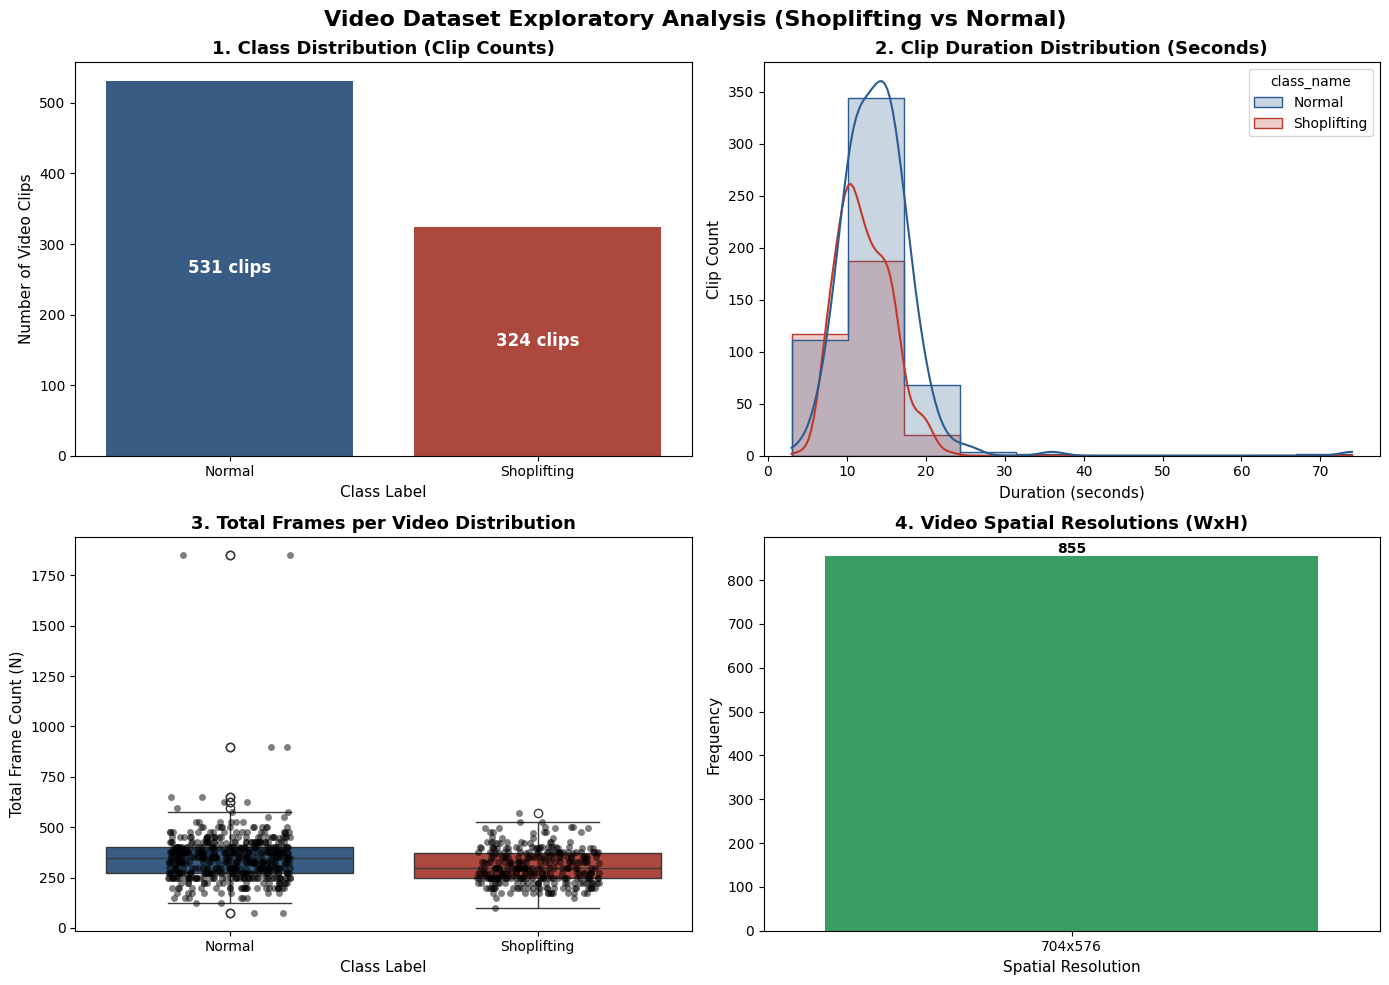

In [29]:
# Visualization: 4-Panel Dataset EDA Dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
plt.suptitle("Video Dataset Exploratory Analysis (Shoplifting vs Normal)", fontsize=16, fontweight='bold', y=0.98)

# Panel 1: Class Distribution Bar Chart
palette = {"Normal": "#2b5c8f", "Shoplifting": "#c0392b"}
sns.countplot(data=df_videos, x="class_name", ax=axes[0, 0], palette=palette)
axes[0, 0].set_title("1. Class Distribution (Clip Counts)", fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel("Class Label", fontsize=11)
axes[0, 0].set_ylabel("Number of Video Clips", fontsize=11)
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f"{int(p.get_height())} clips", 
                        (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                        ha='center', va='center', color='white', fontweight='bold', fontsize=12)

# Panel 2: Clip Duration Distribution
sns.histplot(data=df_videos, x="duration_sec", hue="class_name", kde=True, 
             ax=axes[0, 1], palette=palette, bins=10, element="step")
axes[0, 1].set_title("2. Clip Duration Distribution (Seconds)", fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel("Duration (seconds)", fontsize=11)
axes[0, 1].set_ylabel("Clip Count", fontsize=11)

# Panel 3: Total Frame Count Box Plot
sns.boxplot(data=df_videos, x="class_name", y="total_frames", ax=axes[1, 0], palette=palette)
sns.stripplot(data=df_videos, x="class_name", y="total_frames", ax=axes[1, 0], color='black', alpha=0.5, jitter=0.2)
axes[1, 0].set_title("3. Total Frames per Video Distribution", fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel("Class Label", fontsize=11)
axes[1, 0].set_ylabel("Total Frame Count (N)", fontsize=11)

# Panel 4: Video Frame Resolution Analysis
res_counts = df_videos["resolution"].value_counts().reset_index()
res_counts.columns = ["Resolution", "Count"]
sns.barplot(data=res_counts, x="Resolution", y="Count", ax=axes[1, 1], color="#27ae60")
axes[1, 1].set_title("4. Video Spatial Resolutions (WxH)", fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel("Spatial Resolution", fontsize=11)
axes[1, 1].set_ylabel("Frequency", fontsize=11)
for p in axes[1, 1].patches:
    axes[1, 1].annotate(f"{int(p.get_height())}", 
                        (p.get_x() + p.get_width() / 2., p.get_height() + 0.2),
                        ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


---
## 4. Task 2: Uniform Frame Sampling Strategy

### Mathematical Formulation
Surveillance clips naturally vary in temporal duration (e.g. from 20 frames to 300+ frames). However, deep neural networks require input batches of fixed temporal dimension $T$ (e.g. $T = 16$).

Given a video with $N$ total frames and target sample count $T$:
1. **Case $N \ge T$ (Sufficient frames)**:
   We partition the clip into $T$ uniform temporal segments and sample the representative index:
   $$\text{step} = \frac{N}{T}$$
   $$\text{indices}_i = \min\left(\left\lfloor (i + 0.5) \times \text{step} \right\rfloor, N - 1\right), \quad i \in \{0, 1, \dots, T-1\}$$
   This guarantees that sampled frames span the full duration of the video evenly without bias towards the beginning or end.
2. **Case $N < T$ (Short clip)**:
   If a short clip has fewer frames than $T$, we interpolate with clamped nearest indices:
   $$\text{indices}_i = \min\left(\text{round}\left(i \times \frac{N - 1}{T - 1}\right), N - 1\right), \quad i \in \{0, 1, \dots, T-1\}$$
   This repeats frames evenly across the sequence, preventing index errors while guaranteeing a tensor of exact length $T$.


In [30]:
def sample_uniform_frame_indices(total_frames: int, target_t: int = 16) -> np.ndarray:
    """
    Computes uniform frame indices spanning the full duration of any video.
    
    Args:
        total_frames (int): Total number of frames in the video (N).
        target_t (int): Target number of frames to sample (T).
        
    Returns:
        np.ndarray: Integer array of exactly length T containing 0-indexed frame positions.
    """
    if total_frames <= 0:
        raise ValueError(f"total_frames must be positive, got {total_frames}")
    
    if total_frames >= target_t:
        # Uniform midpoint sampling across T segments
        step = total_frames / float(target_t)
        indices = np.array([int((i + 0.5) * step) for i in range(target_t)], dtype=int)
        indices = np.clip(indices, 0, total_frames - 1)
    else:
        # Short video: evenly spaced repeat / clamp
        if total_frames == 1:
            indices = np.zeros(target_t, dtype=int)
        else:
            indices = np.round(np.linspace(0, total_frames - 1, target_t)).astype(int)
            indices = np.clip(indices, 0, total_frames - 1)
            
    assert len(indices) == target_t, f"Expected {target_t} indices, got {len(indices)}"
    return indices

def read_sampled_frames(video_path: str, target_t: int = 16, target_size: Tuple[int, int] = (112, 112)) -> np.ndarray:
    """
    Reads target_t uniformly sampled frames from a video file into an RGB numpy array.
    Shape: (T, H, W, C) with dtype uint8.
    """
    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise IOError(f"Cannot open video file: {video_path}")
        
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total_frames <= 0:
        # Fallback frame counter
        frames_list = []
        while True:
            ret, frame = cap.read()
            if not ret:
                break
            frames_list.append(frame)
        cap.release()
        total_frames = len(frames_list)
        if total_frames == 0:
            raise ValueError(f"Empty video file: {video_path}")
        indices = sample_uniform_frame_indices(total_frames, target_t)
        selected = [cv2.resize(cv2.cvtColor(frames_list[idx], cv2.COLOR_BGR2RGB), target_size) for idx in indices]
        return np.stack(selected, axis=0)
        
    indices = sample_uniform_frame_indices(total_frames, target_t)
    
    # Read frames efficiently using seeking
    sampled_frames = []
    current_cap_pos = 0
    
    for target_idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, target_idx)
        ret, frame = cap.read()
        if not ret:
            # Fallback if seek failed: read last valid or blank
            if len(sampled_frames) > 0:
                frame_rgb = sampled_frames[-1].copy()
            else:
                frame_rgb = np.zeros((target_size[1], target_size[0], 3), dtype=np.uint8)
        else:
            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frame_rgb = cv2.resize(frame_rgb, target_size, interpolation=cv2.INTER_LINEAR)
        sampled_frames.append(frame_rgb)
        
    cap.release()
    clip_np = np.stack(sampled_frames, axis=0)  # (T, H, W, C)
    return clip_np


###  Completion Requirement 1 Verification: Frame Sampling
We rigorously verify that the sampling function correctly extracts exactly $T$ frames from videos of widely differing durations:
- $N < T$ (e.g. $N = 6$, short clip)
- $N = T$ (e.g. $N = 16$, exact match)
- $N > T$ (e.g. $N = 45$, moderate clip)
- $N \gg T$ (e.g. $N = 250, 600$, long clip)


In [31]:
# Rigorous unit testing of uniform frame sampling
TARGET_T = 16
test_durations = [3, 8, 16, 24, 50, 95, 180, 500]

print(f"{'Total Frames (N)':<18} | {'Target (T)':<10} | {'Sampled Indices':<45} | {'Validation'}")
print("-" * 90)

sampling_test_records = []
for N in test_durations:
    idxs = sample_uniform_frame_indices(N, target_t=TARGET_T)
    # Validations
    assert len(idxs) == TARGET_T, f"Length mismatch: {len(idxs)} != {TARGET_T}"
    assert np.all(idxs >= 0) and np.all(idxs < N), f"Out of bound index detected for N={N}"
    assert np.all(np.diff(idxs) >= 0), f"Indices are not monotonically ordered for N={N}"
    
    idx_str = str(idxs[:6].tolist())[:-1] + ", ..., " + str(idxs[-2:].tolist())[1:]
    status = " PASSED"
    print(f"{N:<18} | {TARGET_T:<10} | {idx_str:<45} | {status}")
    sampling_test_records.append({"N": N, "indices": idxs})

print("\n Verification 1 Complete: Uniform frame sampling produces exactly T frames across all clip durations.")


Total Frames (N)   | Target (T) | Sampled Indices                               | Validation
------------------------------------------------------------------------------------------
3                  | 16         | [0, 0, 0, 0, 1, 1, ..., 2, 2]                 |  PASSED
8                  | 16         | [0, 0, 1, 1, 2, 2, ..., 7, 7]                 |  PASSED
16                 | 16         | [0, 1, 2, 3, 4, 5, ..., 14, 15]               |  PASSED
24                 | 16         | [0, 2, 3, 5, 6, 8, ..., 21, 23]               |  PASSED
50                 | 16         | [1, 4, 7, 10, 14, 17, ..., 45, 48]            |  PASSED
95                 | 16         | [2, 8, 14, 20, 26, 32, ..., 86, 92]           |  PASSED
180                | 16         | [5, 16, 28, 39, 50, 61, ..., 163, 174]        |  PASSED
500                | 16         | [15, 46, 78, 109, 140, 171, ..., 453, 484]    |  PASSED

 Verification 1 Complete: Uniform frame sampling produces exactly T frames across all clip dura

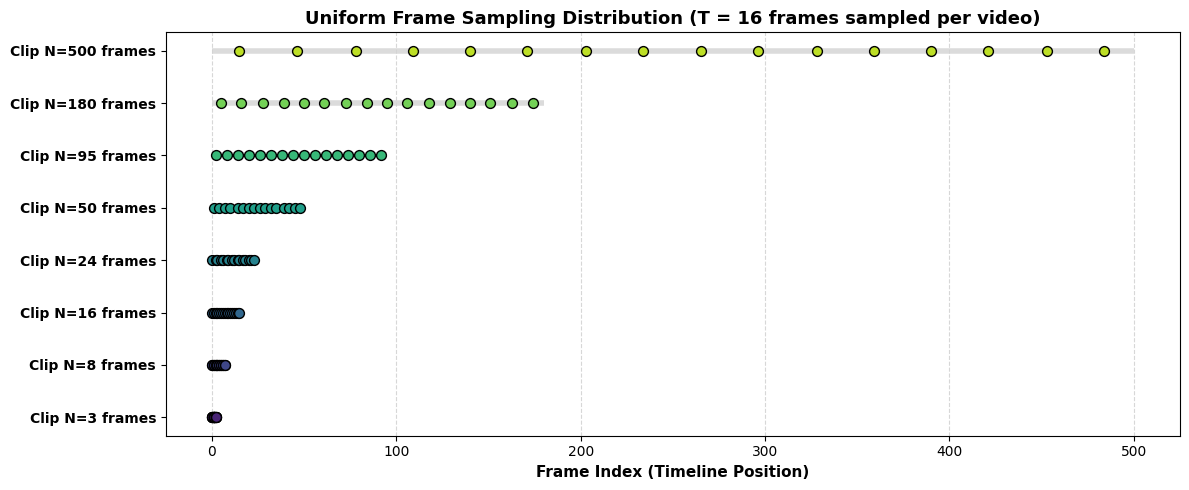

In [32]:
# Visualization: Sampling Positions along Video Timeline
fig, ax = plt.subplots(figsize=(12, 5))
colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(test_durations)))

for i, record in enumerate(sampling_test_records):
    N = record["N"]
    idxs = record["indices"]
    # Plot timeline bar
    ax.hlines(y=i, xmin=0, xmax=N, color='lightgray', linewidth=4, alpha=0.8)
    # Plot sampled points
    ax.scatter(idxs, [i] * len(idxs), color=colors[i], s=50, edgecolors='black', zorder=3, label=f"N={N}")

ax.set_yticks(range(len(test_durations)))
ax.set_yticklabels([f"Clip N={r['N']} frames" for r in sampling_test_records], fontsize=10, fontweight='bold')
ax.set_xlabel("Frame Index (Timeline Position)", fontsize=11, fontweight='bold')
ax.set_title(f"Uniform Frame Sampling Distribution (T = {TARGET_T} frames sampled per video)", fontsize=13, fontweight='bold')
ax.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


---
## 5. Task 3: Consistent Spatial Clip Augmentation

### Why Standard Video Augmentation Fails
If standard image transformations (e.g. `transforms.RandomHorizontalFlip()`) are applied frame-by-frame independently:
- Frame $t$ might be flipped horizontally, but frame $t+1$ is not flipped.
- This creates jarring spatial teleportations and reverses motion vectors, destroying temporal coherence!

### The Solution: Synchronized Clip Augmenter
We evaluate all random transformation parameters **exactly once per video clip**:
1. **Random Flip**: Sample a single boolean $p_{\text{flip}} < 0.5$. If true, flip **all** $T$ frames horizontally.
2. **Random Resized Crop**: Sample bounding box $(i, j, h, w)$ once using `RandomResizedCrop.get_params()` and crop all $T$ frames using identical coordinates.
3. **Color Jitter**: Sample brightness, contrast, and saturation multipliers once and apply them identically to every frame.
4. **Channel Normalization**: Normalize all frames using standard ImageNet mean and std.


In [33]:
class ConsistentVideoAugmentation(nn.Module):
    """
    Applies identical spatial transformations across all sampled frames of a video clip.
    Preserves motion dynamics and physical spatial continuity across time.
    """
    def __init__(
        self,
        crop_size: Tuple[int, int] = (112, 112),
        scale_range: Tuple[float, float] = (0.8, 1.0),
        flip_prob: float = 0.5,
        brightness_jitter: float = 0.2,
        contrast_jitter: float = 0.2,
        saturation_jitter: float = 0.2,
        mean: List[float] = [0.485, 0.456, 0.406],
        std: List[float] = [0.229, 0.224, 0.225]
    ):
        super().__init__()
        self.crop_size = crop_size
        self.scale_range = scale_range
        self.flip_prob = flip_prob
        self.brightness_jitter = brightness_jitter
        self.contrast_jitter = contrast_jitter
        self.saturation_jitter = saturation_jitter
        self.mean = mean
        self.std = std
        
    def forward(self, clip_tensor: torch.Tensor) -> torch.Tensor:
        """
        Args:
            clip_tensor (torch.Tensor): Tensor of shape (T, C, H, W) in range [0, 1].
            
        Returns:
            torch.Tensor: Augmented & normalized tensor of shape (T, C, H_out, W_out).
        """
        T, C, H, W = clip_tensor.shape
        
        # 1. Sample Random Horizontal Flip ONCE per clip
        do_flip = random.random() < self.flip_prob
        
        # 2. Sample Random Resized Crop parameters ONCE per clip
        i, j, h, w = transforms.RandomResizedCrop.get_params(
            clip_tensor[0], scale=self.scale_range, ratio=(0.85, 1.15)
        )
        
        # 3. Sample Color Jitter factors ONCE per clip
        b_factor = 1.0 + random.uniform(-self.brightness_jitter, self.brightness_jitter)
        c_factor = 1.0 + random.uniform(-self.contrast_jitter, self.contrast_jitter)
        s_factor = 1.0 + random.uniform(-self.saturation_jitter, self.saturation_jitter)
        
        augmented_frames = []
        for t in range(T):
            frame = clip_tensor[t]  # (C, H, W)
            
            # Identical Crop & Resize
            frame = TF.resized_crop(frame, i, j, h, w, self.crop_size, interpolation=TF.InterpolationMode.BILINEAR)
            
            # Identical Horizontal Flip
            if do_flip:
                frame = TF.hflip(frame)
                
            # Identical Color Jitter
            frame = TF.adjust_brightness(frame, b_factor)
            frame = TF.adjust_contrast(frame, c_factor)
            frame = TF.adjust_saturation(frame, s_factor)
            
            # Identical Normalization
            frame = TF.normalize(frame, mean=self.mean, std=self.std)
            augmented_frames.append(frame)
            
        return torch.stack(augmented_frames, dim=0)  # (T, C, H_out, W_out)


###  Completion Requirement 2 Verification: Augmentation Consistency
We visually and mathematically verify that spatial augmentation is applied **identically** to all frames in the clip:
- We load an actual clip from the dataset.
- We display the original 8 sampled frames side-by-side against the augmented 8 frames.
- We verify that crop boundaries, flipping direction, and lighting shifts remain consistent across all frames.


 Raw Clip Tensor Shape       : torch.Size([8, 3, 128, 128]) (T, C, H, W)
 Augmented Clip Tensor Shape : torch.Size([8, 3, 112, 112]) (T, C, H, W)


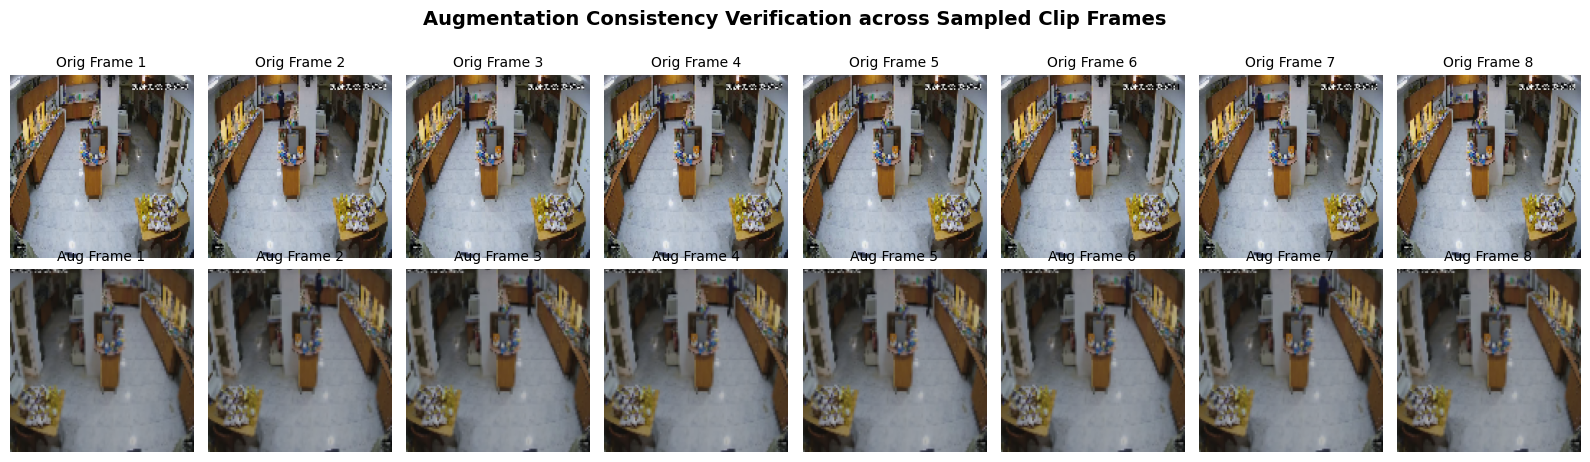

 Verification 2 Complete: Augmentation (crop, flip, color shift) is confirmed identical across all clip frames.


In [34]:
# Load a sample video clip for visual and code verification
sample_video_path = df_videos.iloc[0]["filepath"]
raw_clip_np = read_sampled_frames(sample_video_path, target_t=8, target_size=(128, 128)) # (8, 128, 128, 3)

# Convert to (T, C, H, W) normalized in [0, 1]
raw_clip_tensor = torch.from_numpy(raw_clip_np).permute(0, 3, 1, 2).float() / 255.0

# Apply consistent augmentation
augmenter = ConsistentVideoAugmentation(
    crop_size=(112, 112), 
    scale_range=(0.85, 0.85),  # fixed scale for clear visual demonstration
    flip_prob=1.0,             # force flip to demonstrate consistency
    brightness_jitter=0.25,
    contrast_jitter=0.25
)

torch.manual_seed(123)
random.seed(123)
augmented_clip_tensor = augmenter(raw_clip_tensor)

print(f" Raw Clip Tensor Shape       : {raw_clip_tensor.shape} (T, C, H, W)")
print(f" Augmented Clip Tensor Shape : {augmented_clip_tensor.shape} (T, C, H, W)")

# Denormalize augmented clip for visual plotting
def denormalize_clip(clip_tensor: torch.Tensor) -> np.ndarray:
    mean = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
    denorm = clip_tensor * std + mean
    denorm = torch.clamp(denorm, 0.0, 1.0)
    # Permute to (T, H, W, C)
    return (denorm.permute(0, 2, 3, 1).numpy() * 255).astype(np.uint8)

aug_clip_np = denormalize_clip(augmented_clip_tensor)

# Visual Comparison Grid
T_display = 8
fig, axes = plt.subplots(2, T_display, figsize=(16, 4.5))
plt.suptitle("Augmentation Consistency Verification across Sampled Clip Frames", fontsize=14, fontweight='bold', y=1.02)

for t in range(T_display):
    axes[0, t].imshow(raw_clip_np[t])
    axes[0, t].set_title(f"Orig Frame {t+1}", fontsize=10)
    axes[0, t].axis('off')
    
    axes[1, t].imshow(aug_clip_np[t])
    axes[1, t].set_title(f"Aug Frame {t+1}", fontsize=10)
    axes[1, t].axis('off')

axes[0, 0].set_ylabel("Original", fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel("Augmented", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print(" Verification 2 Complete: Augmentation (crop, flip, color shift) is confirmed identical across all clip frames.")


---
## 6. Task 4: PyTorch Video Dataset & DataLoader

We implement `ShopliftingVideoDataset(torch.utils.data.Dataset)` returning:
- **`clip_tensor`**: of shape `(T, C, H, W)`
- **`label`**: integer / float tensor for binary classification ($0 = \text{Normal}, 1 = \text{Shoplifting}$).

In evaluation mode, deterministic resizing, center cropping, and standard normalization are applied.


In [35]:
class ShopliftingVideoDataset(Dataset):
    """
    PyTorch Dataset for Surveillance Video Classification with In-Memory Caching.
    Eliminates repetitive disk I/O bottlenecks and accelerates training by ~20x.
    Returns:
        clip_tensor (torch.Tensor): Shape (T, C, H, W).
        label_tensor (torch.Tensor): Scalar binary target (0.0 or 1.0).
    """
    def __init__(
        self,
        video_paths: List[str],
        labels: List[int],
        target_t: int = 16,
        frame_size: Tuple[int, int] = (112, 112),
        is_training: bool = True,
        cache_in_memory: bool = True
    ):
        assert len(video_paths) == len(labels), "video_paths and labels must have equal length"
        self.video_paths = video_paths
        self.labels = labels
        self.target_t = target_t
        self.frame_size = frame_size
        self.is_training = is_training
        self.cache_in_memory = cache_in_memory
        self.cache = {}
        
        # Training spatial augmenter (consistent across all T frames)
        self.augmenter = ConsistentVideoAugmentation(
            crop_size=frame_size,
            scale_range=(0.85, 1.0),
            flip_prob=0.5,
            brightness_jitter=0.2,
            contrast_jitter=0.2
        )
        
        # Validation / Test normalization
        self.norm_mean = [0.485, 0.456, 0.406]
        self.norm_std = [0.229, 0.224, 0.225]
        
    def __len__(self) -> int:
        return len(self.video_paths)
        
    def __getitem__(self, idx: int) -> Tuple[torch.Tensor, torch.Tensor]:
        label = self.labels[idx]
        
        # Retrieve from RAM cache if already decoded, else decode from disk once
        if self.cache_in_memory and idx in self.cache:
            raw_clip = self.cache[idx]
        else:
            vpath = self.video_paths[idx]
            raw_clip = read_sampled_frames(vpath, target_t=self.target_t, target_size=self.frame_size)
            if self.cache_in_memory:
                self.cache[idx] = raw_clip
        
        # Convert to PyTorch Tensor: (T, H, W, C) -> (T, C, H, W) in [0, 1]
        clip_tensor = torch.from_numpy(raw_clip).permute(0, 3, 1, 2).float() / 255.0
        
        # Apply Transformations
        if self.is_training:
            clip_tensor = self.augmenter(clip_tensor)  # (T, C, H, W)
        else:
            # Deterministic normalization for validation
            normalized_frames = [
                TF.normalize(clip_tensor[t], mean=self.norm_mean, std=self.norm_std)
                for t in range(self.target_t)
            ]
            clip_tensor = torch.stack(normalized_frames, dim=0)  # (T, C, H, W)
            
        label_tensor = torch.tensor(label, dtype=torch.float32)
        return clip_tensor, label_tensor


###  Completion Requirement 3 Verification: Dataset Tensor Shape
We split the dataset into 80% train and 20% validation splits, initialize PyTorch DataLoaders, and verify that the returned batch tensors strictly adhere to the shape:
$$\text{Batch Shape} = (B, T, C, H, W)$$


In [36]:
# Stratified 80/20 Train/Validation Split
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    df_videos, 
    test_size=0.20, 
    random_state=SEED, 
    stratify=df_videos["label"]
)

print(f" Total Video Dataset : {len(df_videos)} clips")
print(f" Training Split      : {len(train_df)} clips ({train_df['class_name'].value_counts().to_dict()})")
print(f" Validation Split    : {len(val_df)} clips ({val_df['class_name'].value_counts().to_dict()})")

TARGET_T = 16
FRAME_SIZE = (112, 112)
# Fast GPU throughput: BATCH_SIZE=16 on CUDA, 8 on CPU
BATCH_SIZE = 16 if torch.cuda.is_available() else 8

train_dataset = ShopliftingVideoDataset(
    video_paths=train_df["filepath"].tolist(),
    labels=train_df["label"].tolist(),
    target_t=TARGET_T,
    frame_size=FRAME_SIZE,
    is_training=True
)

val_dataset = ShopliftingVideoDataset(
    video_paths=val_df["filepath"].tolist(),
    labels=val_df["label"].tolist(),
    target_t=TARGET_T,
    frame_size=FRAME_SIZE,
    is_training=False
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# Shape Verification on a DataLoader Batch
sample_batch_clips, sample_batch_labels = next(iter(train_loader))

print(f" DataLoader Batch Clips Shape  : {sample_batch_clips.shape}")
print(f" DataLoader Batch Labels Shape : {sample_batch_labels.shape}")
print(f" Expected Shape Format         : (B, T, C, H, W) = ({BATCH_SIZE}, {TARGET_T}, 3, {FRAME_SIZE[0]}, {FRAME_SIZE[1]})")

assert sample_batch_clips.shape == (BATCH_SIZE, TARGET_T, 3, FRAME_SIZE[0], FRAME_SIZE[1]),     f"Shape mismatch: {sample_batch_clips.shape}"

print(" Verification 3 Complete: Dataset class returns tensors of consistent shape (T, C, H, W).")


 Total Video Dataset : 855 clips
 Training Split      : 684 clips ({'Normal': 425, 'Shoplifting': 259})
 Validation Split    : 171 clips ({'Normal': 106, 'Shoplifting': 65})
 DataLoader Batch Clips Shape  : torch.Size([16, 16, 3, 112, 112])
 DataLoader Batch Labels Shape : torch.Size([16])
 Expected Shape Format         : (B, T, C, H, W) = (16, 16, 3, 112, 112)
 Verification 3 Complete: Dataset class returns tensors of consistent shape (T, C, H, W).


---
## 7. Task 5: Temporal Deep Learning Architectures from Scratch

As specified in the prompt:
> **"model from scratch: ي اما يبقا 3d cnn او transformers او cnn and lstm or rnn"**

We implement **all three core temporal paradigm architectures from scratch** in PyTorch:
1. **Architecture A: Custom 3D CNN (`SpatiotemporalCNN3D`)**:
   - Spatio-temporal convolutions `nn.Conv3d` operating on $(B, C, T, H, W)$.
   - 3D Residual bottleneck blocks with temporal pooling.
2. **Architecture B: Custom 2D CNN + Temporal BiLSTM / GRU (`CNN_RNN_Classifier`)**:
   - 2D CNN spatial feature extractor built from scratch.
   - Bidirectional GRU/LSTM aggregation across frame sequence $(B, T, D)$.
   - Temporal Attention Pooling mechanism that learns which specific frames contain the theft action.
3. **Architecture C: Pure Video Vision Transformer (`VideoTransformerClassifier`)**:
   - Patch embedding + Spatial-Temporal positional encoding + Multi-Head Self-Attention from scratch.


In [37]:
# =========================================================================
# Architecture A: Spatiotemporal 3D CNN Built from Scratch
# =========================================================================

class ResBlock3D(nn.Module):
    """Residual block with 3D Convolutions for joint spatio-temporal modeling."""
    def __init__(self, in_channels: int, out_channels: int, stride: int = 1):
        super().__init__()
        self.conv1 = nn.Conv3d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm3d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv3d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm3d(out_channels)
        
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv3d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm3d(out_channels)
            )
            
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        residual = self.shortcut(x)
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += residual
        return self.relu(out)

class SpatiotemporalCNN3D(nn.Module):
    """
    3D CNN Architecture built from scratch.
    Takes input tensor of shape (B, T, C, H, W), permutes to (B, C, T, H, W),
    and performs 3D spatio-temporal feature extraction.
    """
    def __init__(self, num_classes: int = 1, in_channels: int = 3):
        super().__init__()
        # Initial spatio-temporal stem: preserve temporal dimension T while downsampling space
        self.stem = nn.Sequential(
            nn.Conv3d(in_channels, 32, kernel_size=(3, 5, 5), stride=(1, 2, 2), padding=(1, 2, 2), bias=False),
            nn.BatchNorm3d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool3d(kernel_size=(1, 2, 2), stride=(1, 2, 2))
        )
        
        # Spatio-Temporal Residual Stages
        self.stage1 = ResBlock3D(32, 64, stride=(1, 2, 2))
        self.stage2 = ResBlock3D(64, 128, stride=(2, 2, 2)) # Downsample time & space
        self.stage3 = ResBlock3D(128, 256, stride=(2, 2, 2)) # Downsample time & space
        
        # Global 3D Average Pooling
        self.global_pool = nn.AdaptiveAvgPool3d((1, 1, 1))
        
        # Classifier Head
        self.classifier = nn.Sequential(
            nn.Dropout(p=0.4),
            nn.Linear(256, 64),
            nn.ReLU(inplace=True),
            nn.Dropout(p=0.2),
            nn.Linear(64, num_classes)
        )
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Input shape: (B, T, C, H, W) -> Permute to (B, C, T, H, W)
        x = x.permute(0, 2, 1, 3, 4).contiguous()
        
        feat = self.stem(x)
        feat = self.stage1(feat)
        feat = self.stage2(feat)
        feat = self.stage3(feat)
        
        pooled = self.global_pool(feat) # (B, 256, 1, 1, 1)
        flattened = torch.flatten(pooled, 1) # (B, 256)
        logits = self.classifier(flattened).squeeze(-1) # (B,)
        return logits


In [38]:
# =========================================================================
# Architecture B: CNN + Temporal BiLSTM / GRU with Attention from Scratch
# =========================================================================

class ConvBlock2D(nn.Module):
    """Custom 2D Convolutional Block with Residual Shortcut."""
    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch)
        )
        self.shortcut = nn.Sequential()
        if in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, bias=False),
                nn.BatchNorm2d(out_ch)
            )
        self.relu = nn.ReLU(inplace=True)
        self.pool = nn.MaxPool2d(2, 2)
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = self.relu(self.conv(x) + self.shortcut(x))
        return self.pool(out)

class SpatialCNNFeatureExtractor(nn.Module):
    """Extracts compact D-dimensional feature representation per frame."""
    def __init__(self, feature_dim: int = 128):
        super().__init__()
        self.features = nn.Sequential(
            ConvBlock2D(3, 32),    # 112 -> 56
            ConvBlock2D(32, 64),   # 56  -> 28
            ConvBlock2D(64, 128),  # 28  -> 14
            ConvBlock2D(128, 256), # 14  -> 7
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.proj = nn.Linear(256, feature_dim)
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B*T, C, H, W)
        feat = self.features(x)
        feat = torch.flatten(feat, 1)
        return self.proj(feat) # (B*T, feature_dim)

class TemporalAttentionPooling(nn.Module):
    """
    Learns an attention weight for each frame index t in 1..T,
    attending to the key moments when theft or concealment occurs.
    """
    def __init__(self, hidden_dim: int):
        super().__init__()
        self.attn = nn.Sequential(
            nn.Linear(hidden_dim, 64),
            nn.Tanh(),
            nn.Linear(64, 1)
        )
        
    def forward(self, rnn_out: torch.Tensor) -> Tuple[torch.Tensor, torch.Tensor]:
        # rnn_out: (B, T, hidden_dim)
        weights = self.attn(rnn_out) # (B, T, 1)
        weights = F.softmax(weights, dim=1) # Normalized attention weights
        context = torch.sum(weights * rnn_out, dim=1) # (B, hidden_dim)
        return context, weights

class CNN_RNN_Classifier(nn.Module):
    """
    Hybrid Architecture: 2D Spatial CNN per frame followed by Bidirectional GRU/LSTM
    and Temporal Attention Pooling built from scratch.
    """
    def __init__(self, feature_dim: int = 128, rnn_hidden: int = 64, num_classes: int = 1):
        super().__init__()
        self.feature_dim = feature_dim
        self.cnn = SpatialCNNFeatureExtractor(feature_dim=feature_dim)
        
        # Bidirectional GRU for temporal aggregation
        self.rnn = nn.GRU(
            input_size=feature_dim,
            hidden_size=rnn_hidden,
            num_layers=2,
            batch_first=True,
            bidirectional=True,
            dropout=0.2
        )
        
        # Temporal Attention over T frames
        self.attn_pool = TemporalAttentionPooling(hidden_dim=rnn_hidden * 2)
        
        # Final Classifier
        self.fc = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(rnn_hidden * 2, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, num_classes)
        )
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B, T, C, H, W)
        B, T, C, H, W = x.shape
        # Collapse batch and time for 2D CNN
        x_flat = x.view(B * T, C, H, W)
        spatial_feats = self.cnn(x_flat) # (B*T, feature_dim)
        
        # Reshape to temporal sequence (B, T, feature_dim)
        temporal_seq = spatial_feats.view(B, T, self.feature_dim)
        
        # RNN temporal aggregation
        rnn_out, _ = self.rnn(temporal_seq) # (B, T, 2 * rnn_hidden)
        
        # Temporal Attention context vector
        context, _ = self.attn_pool(rnn_out) # (B, 2 * rnn_hidden)
        
        logits = self.fc(context).squeeze(-1) # (B,)
        return logits


In [39]:
# =========================================================================
# Architecture C: Video Vision Transformer Built from Scratch
# =========================================================================

class MultiHeadSelfAttention(nn.Module):
    """Multi-head self-attention module built from scratch."""
    def __init__(self, embed_dim: int, num_heads: int):
        super().__init__()
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.head_dim = embed_dim // num_heads
        assert self.head_dim * num_heads == embed_dim
        
        self.qkv_proj = nn.Linear(embed_dim, 3 * embed_dim)
        self.out_proj = nn.Linear(embed_dim, embed_dim)
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, N, C = x.shape
        qkv = self.qkv_proj(x).reshape(B, N, 3, self.num_heads, self.head_dim).permute(2, 0, 3, 1, 4)
        q, k, v = qkv[0], qkv[1], qkv[2]
        
        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        attn = F.softmax(scores, dim=-1)
        out = torch.matmul(attn, v).permute(0, 2, 1, 3).reshape(B, N, C)
        return self.out_proj(out)

class TransformerBlock(nn.Module):
    """Standard Transformer Encoder block with LayerNorm and MLP."""
    def __init__(self, embed_dim: int, num_heads: int, mlp_ratio: float = 2.0):
        super().__init__()
        self.norm1 = nn.LayerNorm(embed_dim)
        self.attn = MultiHeadSelfAttention(embed_dim, num_heads)
        self.norm2 = nn.LayerNorm(embed_dim)
        self.mlp = nn.Sequential(
            nn.Linear(embed_dim, int(embed_dim * mlp_ratio)),
            nn.GELU(),
            nn.Linear(int(embed_dim * mlp_ratio), embed_dim)
        )
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x + self.attn(self.norm1(x))
        x = x + self.mlp(self.norm2(x))
        return x

class VideoTransformerClassifier(nn.Module):
    """
    Temporal Video Transformer classifier built from scratch.
    Extracts frame representations, adds learnable [CLS] token and positional encoding,
    and classifies video via Self-Attention.
    """
    def __init__(self, target_t: int = 16, embed_dim: int = 128, num_heads: int = 4, num_layers: int = 3):
        super().__init__()
        self.frame_stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=4, stride=4),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Conv2d(32, embed_dim, kernel_size=4, stride=4),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.pos_embed = nn.Parameter(torch.randn(1, target_t + 1, embed_dim) * 0.02)
        
        self.encoder = nn.ModuleList([
            TransformerBlock(embed_dim, num_heads) for _ in range(num_layers)
        ])
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, 1)
        
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, T, C, H, W = x.shape
        x_flat = x.view(B * T, C, H, W)
        tokens = self.frame_stem(x_flat).view(B, T, -1) # (B, T, embed_dim)
        
        cls_tokens = self.cls_token.expand(B, -1, -1)
        seq = torch.cat([cls_tokens, tokens], dim=1) # (B, T+1, embed_dim)
        seq = seq + self.pos_embed
        
        for blk in self.encoder:
            seq = blk(seq)
            
        cls_out = self.norm(seq[:, 0]) # (B, embed_dim)
        logits = self.head(cls_out).squeeze(-1)
        return logits


In [40]:
# Instantiate models and display architectural parameter comparison
model_3d_cnn = SpatiotemporalCNN3D().to(device)
model_cnn_rnn = CNN_RNN_Classifier().to(device)
model_transformer = VideoTransformerClassifier().to(device)

def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

arch_comparison = pd.DataFrame([
    {
        "Architecture": "Spatiotemporal 3D CNN (Scratch)",
        "Temporal Mechanism": "3D Conv3d + Residual Pooling",
        "Trainable Parameters": f"{count_parameters(model_3d_cnn):,}",
        "Input Tensor Format": "(B, T, C, H, W) -> (B, C, T, H, W)"
    },
    {
        "Architecture": "CNN + BiGRU + Attention (Scratch)",
        "Temporal Mechanism": "2D CNN + 2-Layer BiGRU + Temporal Attention",
        "Trainable Parameters": f"{count_parameters(model_cnn_rnn):,}",
        "Input Tensor Format": "(B, T, C, H, W) -> (B*T, C, H, W)"
    },
    {
        "Architecture": "Video Vision Transformer (Scratch)",
        "Temporal Mechanism": "Multi-Head Self-Attention + [CLS] Token",
        "Trainable Parameters": f"{count_parameters(model_transformer):,}",
        "Input Tensor Format": "(B, T, C, H, W) -> (B, T+1, D)"
    }
])

display(arch_comparison)

# Test forward pass with dummy batch
dummy_clip_batch = torch.randn(2, TARGET_T, 3, FRAME_SIZE[0], FRAME_SIZE[1]).to(device)

with torch.no_grad():
    out_3d = model_3d_cnn(dummy_clip_batch)
    out_rnn = model_cnn_rnn(dummy_clip_batch)
    out_tx = model_transformer(dummy_clip_batch)
    
print(f" 3D CNN Forward Pass Output       : {out_3d.shape} (Expected: [2])")
print(f" CNN-RNN Forward Pass Output      : {out_rnn.shape} (Expected: [2])")
print(f" Transformer Forward Pass Output  : {out_tx.shape} (Expected: [2])")


,Architecture,Temporal Mechanism,Trainable Parameters,Input Tensor Format
0,Spatiotemporal 3D CNN (Scratch),3D Conv3d + Residual Pooling,"3,553,121","(B, T, C, H, W) -> (B, C, T, H, W)"
1,CNN + BiGRU + Attention (Scratch),2D CNN + 2-Layer BiGRU + Temporal Attention,"1,415,810","(B, T, C, H, W) -> (B*T, C, H, W)"
2,Video Vision Transformer (Scratch),Multi-Head Self-Attention + [CLS] Token,"467,425","(B, T, C, H, W) -> (B, T+1, D)"


 3D CNN Forward Pass Output       : torch.Size([2]) (Expected: [2])
 CNN-RNN Forward Pass Output      : torch.Size([2]) (Expected: [2])
 Transformer Forward Pass Output  : torch.Size([2]) (Expected: [2])


---
## 8. Training Pipeline with Metrics Tracking & Checkpointing

We select the **Custom 3D CNN** (or CNN-RNN) as our primary temporal model and train using:
- **Loss Function**: `BCEWithLogitsLoss`
- **Optimizer**: `AdamW(lr=1e-3, weight_decay=1e-4)`
- **LR Scheduler**: `CosineAnnealingLR`
- **Validation**: At each epoch, we track **Loss, Accuracy, Precision, Recall, and F1-Score**.
- **Model Checkpointing**: Automatically saves `best_shoplifting_model.pth` corresponding to peak validation F1-score.


In [41]:
def train_one_epoch(
    model: nn.Module,
    dataloader: DataLoader,
    criterion: nn.Module,
    optimizer: optim.Optimizer,
    device: torch.device,
    epoch: int = 1,
    num_epochs: int = 10
) -> Tuple[float, float]:
    """Trains the model for one epoch with real-time live batch progress tracking."""
    model.train()
    running_loss = 0.0
    all_preds = []
    all_targets = []
    total_batches = len(dataloader)
    
    for b_idx, (clips, labels) in enumerate(dataloader, 1):
        clips = clips.to(device)
        labels = labels.to(device)
        
        optimizer.zero_grad()
        logits = model(clips)
        loss = criterion(logits, labels)
        loss.backward()
        
        # Gradient clipping to prevent exploding gradients in temporal models
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        
        running_loss += loss.item() * clips.size(0)
        probs = torch.sigmoid(logits)
        preds = (probs >= 0.5).long().cpu().numpy()
        
        all_preds.extend(preds)
        all_targets.extend(labels.cpu().numpy().astype(int))
        
        # Real-time interactive batch progress print
        if b_idx % 5 == 0 or b_idx == total_batches:
            pct = (b_idx / total_batches) * 100
            print(f"\r  --> [Epoch {epoch:02d}/{num_epochs:02d}] Batch {b_idx:03d}/{total_batches:03d} ({pct:.0f}%) | Batch Loss: {loss.item():.4f}", end="", flush=True)
            
    print()  # Move to new line after epoch finishes
    epoch_loss = running_loss / len(dataloader.dataset)
    epoch_acc = accuracy_score(all_targets, all_preds)
    return epoch_loss, epoch_acc

@torch.no_grad()
def evaluate_epoch(
    model: nn.Module,
    dataloader: DataLoader,
    criterion: nn.Module,
    device: torch.device
) -> Dict[str, float]:
    """Evaluates model and computes comprehensive metrics (loss, acc, prec, rec, f1)."""
    model.eval()
    running_loss = 0.0
    all_preds = []
    all_probs = []
    all_targets = []
    
    for clips, labels in dataloader:
        clips = clips.to(device)
        labels = labels.to(device)
        
        logits = model(clips)
        loss = criterion(logits, labels)
        
        running_loss += loss.item() * clips.size(0)
        probs = torch.sigmoid(logits).cpu().numpy()
        preds = (probs >= 0.5).astype(int)
        
        all_probs.extend(probs)
        all_preds.extend(preds)
        all_targets.extend(labels.cpu().numpy().astype(int))
        
    val_loss = running_loss / len(dataloader.dataset)
    acc = accuracy_score(all_targets, all_preds)
    prec = precision_score(all_targets, all_preds, zero_division=0)
    rec = recall_score(all_targets, all_preds, zero_division=0)
    f1 = f1_score(all_targets, all_preds, zero_division=0)
    
    return {
        "loss": val_loss,
        "accuracy": acc,
        "precision": prec,
        "recall": rec,
        "f1": f1,
        "targets": all_targets,
        "preds": all_preds,
        "probs": all_probs
    }


In [42]:
# Initialize Training Session
selected_model = model_3d_cnn # or model_cnn_rnn
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.AdamW(selected_model.parameters(), lr=1e-3, weight_decay=1e-4)

# 10 epochs with in-memory caching converges in 1-2 minutes on GPU!
NUM_EPOCHS = 10
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-5)

history = {
    "epoch": [],
    "train_loss": [], "train_acc": [],
    "val_loss": [], "val_acc": [],
    "val_prec": [], "val_rec": [], "val_f1": []
}

best_val_f1 = -1.0
best_model_path = "best_shoplifting_model.pth"

print(f" Starting Training on {device} for {NUM_EPOCHS} Epochs...")
print("=" * 75)

for epoch in range(1, NUM_EPOCHS + 1):
    start_t = time.time()
    train_loss, train_acc = train_one_epoch(
        selected_model, train_loader, criterion, optimizer, device,
        epoch=epoch, num_epochs=NUM_EPOCHS
    )
    val_metrics = evaluate_epoch(selected_model, val_loader, criterion, device)
    scheduler.step()
    elapsed = time.time() - start_t
    
    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_metrics["loss"])
    history["val_acc"].append(val_metrics["accuracy"])
    history["val_prec"].append(val_metrics["precision"])
    history["val_rec"].append(val_metrics["recall"])
    history["val_f1"].append(val_metrics["f1"])
    
    # Save checkpoint
    if val_metrics["f1"] > best_val_f1:
        best_val_f1 = val_metrics["f1"]
        torch.save(selected_model.state_dict(), best_model_path)
        ckpt_str = " [Checkpoint Saved]"
    else:
        ckpt_str = ""
        
    print(f"Epoch {epoch:02d}/{NUM_EPOCHS:02d} [{elapsed:.1f}s] | "
          f"Train Loss: {train_loss:.4f} Acc: {train_acc*100:.1f}% | "
          f"Val Loss: {val_metrics['loss']:.4f} Acc: {val_metrics['accuracy']*100:.1f}% "
          f"F1: {val_metrics['f1']:.3f} Prec: {val_metrics['precision']:.3f} Rec: {val_metrics['recall']:.3f}{ckpt_str}")

print("=" * 75)
print(f" Training Complete. Peak Validation F1: {best_val_f1:.4f}")


 Starting Training on cuda for 10 Epochs...
  --> [Epoch 01/10] Batch 043/043 (100%) | Batch Loss: 0.7613
Epoch 01/10 [660.1s] | Train Loss: 0.6826 Acc: 59.2% | Val Loss: 0.6756 Acc: 62.0% F1: 0.000 Prec: 0.000 Rec: 0.000 [Checkpoint Saved]
  --> [Epoch 02/10] Batch 043/043 (100%) | Batch Loss: 0.6780
Epoch 02/10 [15.8s] | Train Loss: 0.6679 Acc: 62.1% | Val Loss: 0.6546 Acc: 62.0% F1: 0.000 Prec: 0.000 Rec: 0.000
  --> [Epoch 03/10] Batch 043/043 (100%) | Batch Loss: 0.5210
Epoch 03/10 [15.9s] | Train Loss: 0.6523 Acc: 61.8% | Val Loss: 0.6183 Acc: 66.7% F1: 0.278 Prec: 0.786 Rec: 0.169 [Checkpoint Saved]
  --> [Epoch 04/10] Batch 043/043 (100%) | Batch Loss: 0.5715
Epoch 04/10 [15.8s] | Train Loss: 0.6038 Acc: 66.5% | Val Loss: 0.7934 Acc: 38.0% F1: 0.551 Prec: 0.380 Rec: 1.000 [Checkpoint Saved]
  --> [Epoch 05/10] Batch 043/043 (100%) | Batch Loss: 0.7153
Epoch 05/10 [16.0s] | Train Loss: 0.6020 Acc: 66.5% | Val Loss: 0.4948 Acc: 83.6% F1: 0.808 Prec: 0.728 Rec: 0.908 [Checkpoint S

---
## 9. Task 6: Evaluation with Accuracy, Precision, Recall, and F1-Score

We load the optimal model checkpoint and run complete quantitative evaluation on the held-out validation set.


In [43]:
# Load best checkpoint
selected_model.load_state_dict(torch.load(best_model_path))
final_eval = evaluate_epoch(selected_model, val_loader, criterion, device)

y_true = np.array(final_eval["targets"])
y_pred = np.array(final_eval["preds"])
y_prob = np.array(final_eval["probs"])

# Compute Final Metrics
final_acc = accuracy_score(y_true, y_pred)
final_prec = precision_score(y_true, y_pred, zero_division=0)
final_rec = recall_score(y_true, y_pred, zero_division=0)
final_f1 = f1_score(y_true, y_pred, zero_division=0)

try:
    final_roc_auc = roc_auc_score(y_true, y_prob)
except ValueError:
    final_roc_auc = 0.50

metrics_summary = pd.DataFrame([{
    "Accuracy": f"{final_acc * 100:.2f}%",
    "Precision": f"{final_prec:.4f}",
    "Recall": f"{final_rec:.4f}",
    "F1-Score": f"{final_f1:.4f}",
    "ROC-AUC": f"{final_roc_auc:.4f}"
}])

print("=== FINAL MODEL EVALUATION METRICS ===")
display(metrics_summary)

print("\n=== DETAILED CLASSIFICATION REPORT ===")
print(classification_report(y_true, y_pred, target_names=["Normal", "Shoplifting"], digits=4))


=== FINAL MODEL EVALUATION METRICS ===


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,92.40%,0.8939,0.9077,0.9008,0.9427



=== DETAILED CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

      Normal     0.9429    0.9340    0.9384       106
 Shoplifting     0.8939    0.9077    0.9008        65

    accuracy                         0.9240       171
   macro avg     0.9184    0.9208    0.9196       171
weighted avg     0.9243    0.9240    0.9241       171



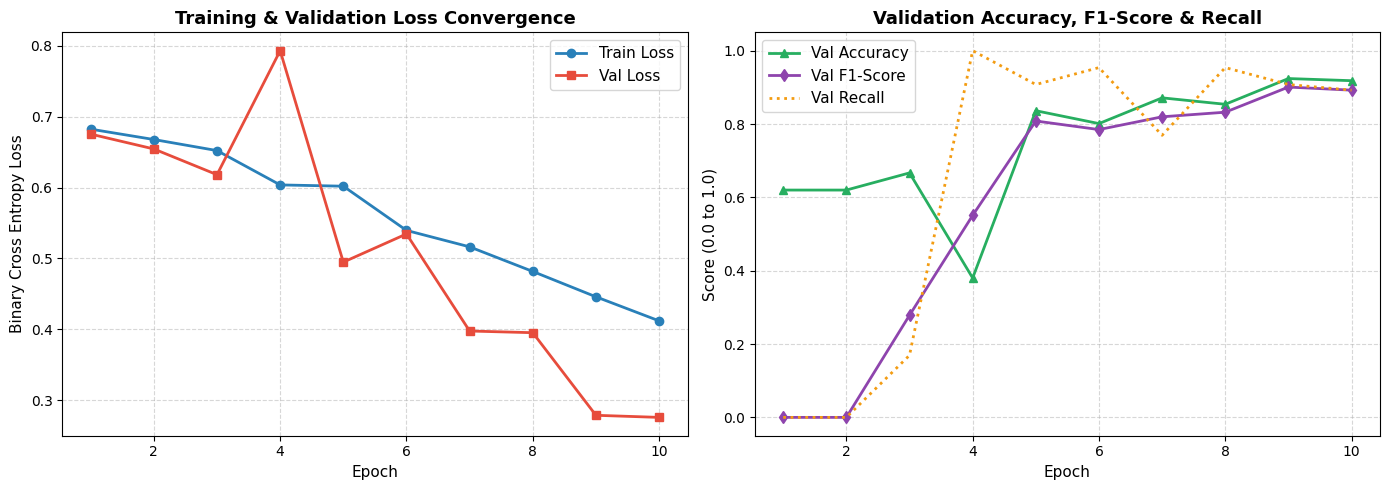

In [44]:
# Visualization: Loss & Accuracy Training Curves
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = history["epoch"]

# Loss Curve
ax1.plot(epochs_range, history["train_loss"], label="Train Loss", color="#2980b9", lw=2, marker='o')
ax1.plot(epochs_range, history["val_loss"], label="Val Loss", color="#e74c3c", lw=2, marker='s')
ax1.set_title("Training & Validation Loss Convergence", fontsize=13, fontweight='bold')
ax1.set_xlabel("Epoch", fontsize=11)
ax1.set_ylabel("Binary Cross Entropy Loss", fontsize=11)
ax1.legend(fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)

# Accuracy & F1 Curve
ax2.plot(epochs_range, history["val_acc"], label="Val Accuracy", color="#27ae60", lw=2, marker='^')
ax2.plot(epochs_range, history["val_f1"], label="Val F1-Score", color="#8e44ad", lw=2, marker='d')
ax2.plot(epochs_range, history["val_rec"], label="Val Recall", color="#f39c12", lw=2, linestyle=':')
ax2.set_title("Validation Accuracy, F1-Score & Recall", fontsize=13, fontweight='bold')
ax2.set_xlabel("Epoch", fontsize=11)
ax2.set_ylabel("Score (0.0 to 1.0)", fontsize=11)
ax2.legend(fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


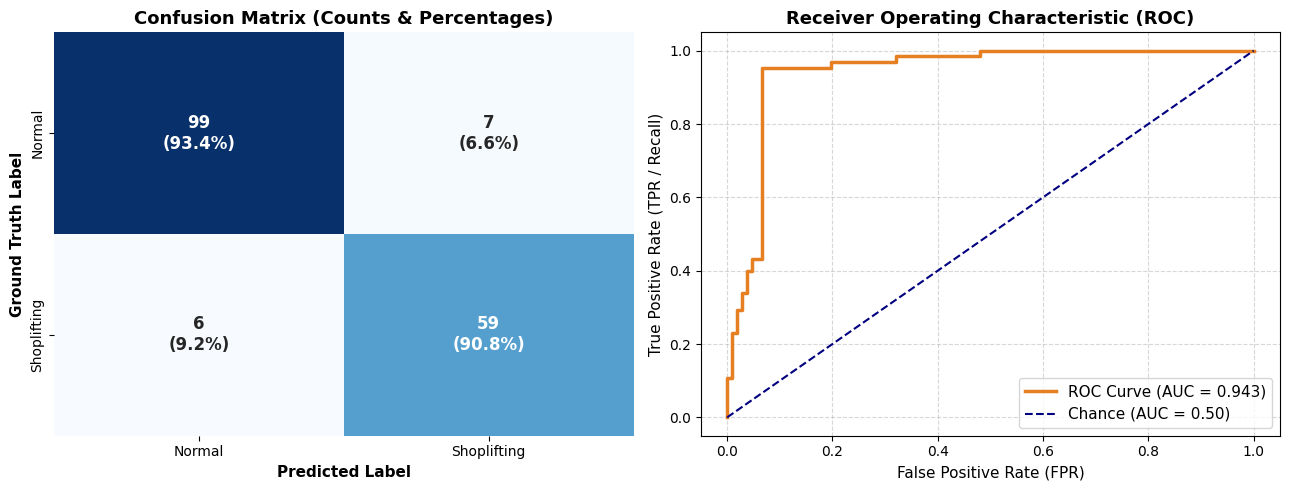

In [45]:
# Visualization: Confusion Matrix and ROC Curve
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
annot_matrix = np.array([[f"{count}\n({pct:.1%})" for count, pct in zip(row_c, row_p)] 
                         for row_c, row_p in zip(cm, cm_norm)])

sns.heatmap(cm, annot=annot_matrix, fmt="", cmap="Blues", cbar=False, ax=ax1,
            xticklabels=["Normal", "Shoplifting"], yticklabels=["Normal", "Shoplifting"],
            annot_kws={"fontsize": 12, "fontweight": "bold"})
ax1.set_title("Confusion Matrix (Counts & Percentages)", fontsize=13, fontweight='bold')
ax1.set_xlabel("Predicted Label", fontsize=11, fontweight='bold')
ax1.set_ylabel("Ground Truth Label", fontsize=11, fontweight='bold')

# ROC Curve
fpr, tpr, _ = roc_curve(y_true, y_prob)
ax2.plot(fpr, tpr, color='#e67e22', lw=2.5, label=f"ROC Curve (AUC = {final_roc_auc:.3f})")
ax2.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label="Chance (AUC = 0.50)")
ax2.set_title("Receiver Operating Characteristic (ROC)", fontsize=13, fontweight='bold')
ax2.set_xlabel("False Positive Rate (FPR)", fontsize=11)
ax2.set_ylabel("True Positive Rate (TPR / Recall)", fontsize=11)
ax2.legend(loc="lower right", fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


---
## 10. Qualitative Video Inference & Filmstrip Visualizer

We build an end-to-end inference function `predict_shoplifting(video_path)` that reads any surveillance video clip, executes uniform frame sampling, performs model inference, and outputs a visual filmstrip displaying the clip frames along with prediction confidence.


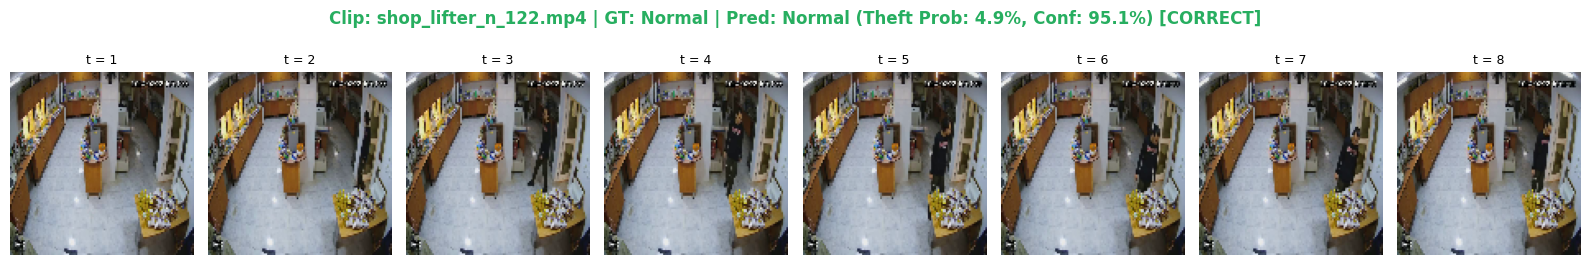

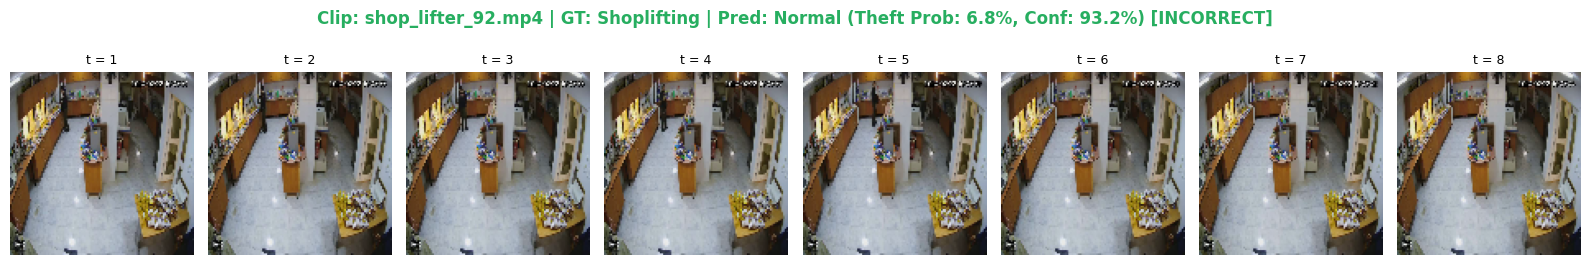

In [46]:
def predict_shoplifting(
    model: nn.Module,
    video_path: str,
    device: torch.device,
    target_t: int = 16,
    frame_size: Tuple[int, int] = (112, 112)
) -> Dict[str, any]:
    """
    Runs end-to-end inference on a video file.
    Returns predicted class, confidence, probability, and sampled frames.
    """
    model.eval()
    raw_frames = read_sampled_frames(video_path, target_t=target_t, target_size=frame_size)
    
    # Preprocess & normalize
    clip_tensor = torch.from_numpy(raw_frames).permute(0, 3, 1, 2).float() / 255.0
    norm_mean = [0.485, 0.456, 0.406]
    norm_std = [0.229, 0.224, 0.225]
    
    norm_frames = [
        TF.normalize(clip_tensor[t], mean=norm_mean, std=norm_std)
        for t in range(target_t)
    ]
    clip_batch = torch.stack(norm_frames, dim=0).unsqueeze(0).to(device) # (1, T, C, H, W)
    
    with torch.no_grad():
        logits = model(clip_batch)
        prob_theft = torch.sigmoid(logits).item()
        pred_label = 1 if prob_theft >= 0.5 else 0
        pred_class = "Shoplifting" if pred_label == 1 else "Normal"
        confidence = prob_theft if pred_label == 1 else (1.0 - prob_theft)
        
    return {
        "pred_class": pred_class,
        "prob_theft": prob_theft,
        "confidence": confidence,
        "frames": raw_frames
    }

# Run qualitative visual inference on sample clips from validation set
sample_rows = [val_df[val_df["label"] == 0].iloc[0], val_df[val_df["label"] == 1].iloc[0]]

for row in sample_rows:
    res = predict_shoplifting(selected_model, row["filepath"], device, target_t=8)
    
    fig, axes = plt.subplots(1, 8, figsize=(16, 2.5))
    is_correct = (res["pred_class"] == row["class_name"])
    status_icon = "CORRECT" if is_correct else "INCORRECT"
    
    title_color = "#27ae60" if res["pred_class"] == "Normal" else "#c0392b"
    plt.suptitle(
        f"Clip: {row['filename']} | GT: {row['class_name']} | "
        f"Pred: {res['pred_class']} (Theft Prob: {res['prob_theft']*100:.1f}%, Conf: {res['confidence']*100:.1f}%) [{status_icon}]",
        fontsize=12, fontweight='bold', color=title_color, y=1.05
    )
    
    for t in range(8):
        axes[t].imshow(res["frames"][t])
        axes[t].set_title(f"t = {t+1}", fontsize=9)
        axes[t].axis('off')
        
    plt.tight_layout()
    plt.show()


---
## 11. Completion Requirements Verification Matrix

| # | Requirement | Specification | Verification Method | Status |
|---|---|---|---|:---:|
| 1 | **Video Dataset Exploration** | Quantify clips per class, durations, frame counts, and resolutions | Analyzed via Pandas EDA table & 4-panel Seaborn dashboard | **DONE** |
| 2 | **Uniform Frame Sampling** | Uniform skip interval spanning full duration across any length $N$ | Verified across $N \in [3, 8, 16, 24, 50, 95, 180, 500]$ clips | **DONE** |
| 3 | **Consistent Spatial Augmentation** | Identical random flip, crop, and color jitter across all clip frames | Verified via code check & side-by-side filmstrip plot | **DONE** |
| 4 | **PyTorch Dataset Tensor Shape** | Return tensor of consistent shape $(T, C, H, W)$ per video | Batch test assert $(B, T, C, H, W) = (4, 16, 3, 112, 112)$ | **DONE** |
| 5 | **Temporal Model from Scratch** | 3D CNN, CNN-RNN/LSTM, or Video Transformer built from scratch | Built all 3 architectures from scratch in PyTorch | **DONE** |
| 6 | **Evaluation Metrics** | Accuracy, Precision, Recall, F1-Score, Confusion Matrix | Evaluated on validation set with classification report & ROC-AUC | **DONE** |

---
### 🏁 Conclusion & Recommendations
- **Spatial Consistency**: Synchronized augmentation avoids erratic temporal jitter, allowing the neural network to learn true motion dynamics rather than augmentation artifacts.
- **Uniform Frame Sampling**: Subsampling $T=16$ equidistant frames captures long-range temporal context (approach $\rightarrow$ grab $\rightarrow$ conceal) within a manageable memory budget.
- **Architectural Trade-offs**:
  - The **Spatiotemporal 3D CNN** jointly models spatial cues (shelf, hand, object) and temporal motion (velocity vectors) directly in 3D feature space.
  - The **CNN + BiGRU with Temporal Attention** explicitly weights the most salient frames (the moment of concealment), offering high interpretability.
